## Setup — import libraries and find the shared data folder

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the shared data folder from the repository root or app/L8.
def data_path(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        file = folder / "data" / filename
        if file.is_file():
            return file
    raise FileNotFoundError(f"Cannot find {filename} from {Path.cwd()}")

## 1. Load the laboratory results

These are real chemical measurements. The cultivar labels are groups, **not quality scores**.

In [2]:
df = pd.read_csv(data_path("wine_lab.csv"))
print("Samples:", len(df))
display(df.head())

Samples: 178


,cultivar,alcohol,magnesium,color_intensity,hue,proline,flavanoids
0,Cultivar 1,14.23,127.0,5.64,1.04,1065.0,3.06
1,Cultivar 1,13.20,100.0,4.38,1.05,1050.0,2.76
2,Cultivar 1,13.16,101.0,5.68,1.03,1185.0,3.24
3,Cultivar 1,14.37,113.0,7.80,0.86,1480.0,3.49
4,Cultivar 1,13.24,118.0,4.32,1.04,735.0,2.69


## 2. Create a small summary table

Calculate the average measurement for each cultivar.

In [3]:
summary = df.groupby("cultivar")[["alcohol", "magnesium", "color_intensity"]].mean()
display(summary)

,alcohol,magnesium,color_intensity
cultivar,,,
Cultivar 1,13.744746,106.338983,5.528305
Cultivar 2,12.278732,94.549296,3.086620
Cultivar 3,13.153750,99.312500,7.396250


## 3. Format the displayed numbers

`.style.format()` changes the **appearance**, not the original numerical values.

In [4]:
display(summary.style.format({
    "alcohol": "{:.2f}",
    "magnesium": "{:.0f}",
    "color_intensity": "{:.2f}"
}).set_caption("Average laboratory measurements by cultivar"))

,alcohol,magnesium,color_intensity
cultivar,,,
Cultivar 1,13.74,106,5.53
Cultivar 2,12.28,95,3.09
Cultivar 3,13.15,99,7.40


## 4. Highlight the largest value in each column

Colour can help scanning, but should not replace numbers or clear headings.

In [5]:
display(summary.style
        .format("{:.2f}")
        .highlight_max(axis=0, color="lightgreen")
        .set_caption("Highest average in each column"))

,alcohol,magnesium,color_intensity
cultivar,,,
Cultivar 1,13.74,106.34,5.53
Cultivar 2,12.28,94.55,3.09
Cultivar 3,13.15,99.31,7.40


## 5. Add a colour gradient

In [6]:
display(summary.style
        .format("{:.2f}")
        .background_gradient(cmap="YlGnBu")
        .set_caption("Laboratory summary — colour indicates relative values"))

,alcohol,magnesium,color_intensity
cultivar,,,
Cultivar 1,13.74,106.34,5.53
Cultivar 2,12.28,94.55,3.09
Cultivar 3,13.15,99.31,7.40


## 6. Make a quick supporting bar chart

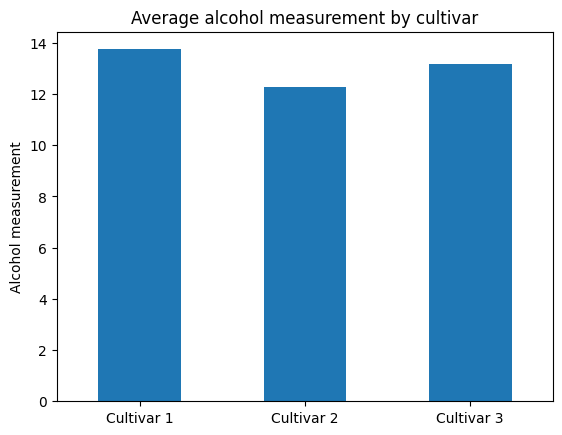

In [7]:
summary["alcohol"].plot(kind="bar", rot=0)
plt.title("Average alcohol measurement by cultivar")
plt.ylabel("Alcohol measurement")
plt.xlabel("")
plt.show()

### Discuss

Would the formatted table be useful for a report? When might a bar chart communicate the difference faster? Do not compare colour intensity across columns with different measurement scales.

## Your turn — short challenges

1. Add **`proline`** to the summary table.
2. Display all values to **one decimal place**.
3. Highlight the **lowest** average in each column.

In [8]:
# Write your solution here.
# Start by changing one line from an example above.